# Example 3.5：Acrobot 与 Cart-Pole 的 LQR 分析

本 notebook 只针对课程 **Example 3.5 (LQR for the Acrobot and Cart-Pole)** 的 LQR 部分：线性化、可控性、LQR 权重、鲁棒性与执行器饱和。

- 原始实验文件：`Exp3'5-acrobot.ipynb`、`Exp3'5-cartpole.ipynb`（未修改）
- 复用已有的分析模块：`exp1_analysis/exp1_analysis.py`、`exp3_2_analysis/cp_analysis.py`
- 对应报告：`Exp3'5-LQR-作业解答.md`
- 结果可复现：`exp3_5_analysis/lqr_comparison.py`

下面的 cell 不依赖 MeshCat，可以直接按顺序运行。


In [1]:

# ===== Example 3.5 LQR 分析：公共设置 =====
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

# 自动定位 Ch.3-examples 目录（无论从哪个目录启动 kernel）
CANDIDATES = [
    os.getcwd(),
    os.path.join(os.getcwd(), "Ch-3", "Ch.3-examples"),
    os.path.join(os.getcwd(), "Embodied-AI", "Ch-3", "Ch.3-examples"),
    os.path.join(os.getcwd(), "Ch.3-examples"),
    os.path.join(os.getcwd(), "Embodied-AI", "Ch.3-examples"),
]
HERE = next(
    (p for p in CANDIDATES
     if os.path.exists(os.path.join(p, "exp1_analysis", "exp1_analysis.py"))),
    None,
)
assert HERE is not None, "未找到 Ch.3-examples 目录，请先把工作目录切换过去"

for sub in ["exp1_analysis", "exp3_2_analysis"]:
    sys.path.insert(0, os.path.join(HERE, sub))
import exp1_analysis as acro   # Acrobot 已验证的 helper
import cp_analysis as cp       # Cart-Pole 已验证的 helper

# 注意：两个 helper 模块内部会调用 matplotlib.use("Agg")，
# 所以要在 import 之后再切回 inline 后端。
%matplotlib inline
plt.rcParams.update({
    "font.sans-serif": ["Arial Unicode MS", "Hiragino Sans GB"],
    "axes.unicode_minus": False,
    "figure.dpi": 120,
})
np.set_printoptions(precision=4, suppress=True, linewidth=180)

FIG = os.path.join(HERE, "exp3_5_analysis", "figures")
os.makedirs(FIG, exist_ok=True)
print("分析目录:", HERE)


分析目录: /Users/leo/Desktop/研究生/机器人与具身智能/Embodied-AI/Ch-3/Ch.3-examples


## 1. 线性化与可控性

计算两者的 $A,B$、开环特征值、能控性奇异值、右半平面零点和 LQR 闭环极点。

=== Acrobot 线性化 ===
A =
 [[  0.       0.       1.       0.    ]
 [  0.       0.       0.       1.    ]
 [ 12.6292 -12.6926  -0.1721   0.3015]
 [-14.7488  29.6119   0.3015  -0.6033]]
B = [ 0.      0.     -3.0147  6.0332]
开环特征值: [-6.492 +0.j -2.2486+0.j  2.2314+0.j  5.7337+0.j]
rank(C)=4, σ(C) = [511.7187 123.0843   0.0807   0.0715]  cond = 7153.636350376389
RHP 零点: {'theta1': [-2.0519016616749837, 2.051901661674984], 'theta2': [-2.3041054906783467, 2.282660069275817]}
LQR D = [278.4422 112.2913 119.7246  56.8282]  闭环极点: [-10.1259+0.j      -4.2381+0.j      -2.2421-0.0387j  -2.2421+0.0387j]

=== Cart-Pole 线性化 ===
A =
 [[ 0.     0.     1.     0.   ]
 [ 0.     0.     0.     1.   ]
 [ 0.     0.981  0.     0.   ]
 [ 0.    21.582  0.     0.   ]]
B = [0.  0.  0.1 0.2]
开环特征值: [-4.6456+0.j  0.    +0.j  0.    +0.j  4.6456+0.j]
rank(C)=4, σ(C) = [4.3257 4.3257 0.0907 0.0907]  cond = 47.684950021774156
RHP 零点: {'u->x': [-4.42944691807002, 4.42944691807002], 'u->θ': [0.0, 0.0]}
LQR D = [   3.1623 -25

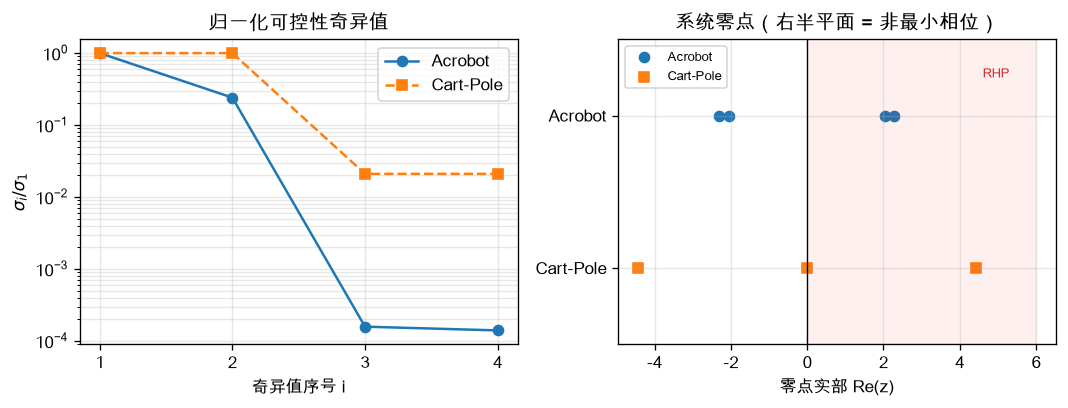

In [2]:

aL = acro.linear_data()
cL = cp.linear_data()
aD = acro.design_controller().D().ravel()
cD = cp.design().D().ravel()
a_cl = np.linalg.eigvals(aL["A"] + aL["B"] @ aD.reshape(1, -1))
c_cl = np.linalg.eigvals(cL["A"] + cL["B"] @ cD.reshape(1, -1))

print("=== Acrobot 线性化 ===")
print("A =\n", aL["A"])
print("B =", aL["B"].ravel())
print("开环特征值:", np.sort_complex(aL["eig"]))
print("rank(C)=4, σ(C) =", aL["sv"], " cond =", aL["cond"])
print("RHP 零点:", aL["zeros"])
print("LQR D =", aD, " 闭环极点:", np.sort_complex(a_cl))

print("\n=== Cart-Pole 线性化 ===")
print("A =\n", cL["A"])
print("B =", cL["B"].ravel())
print("开环特征值:", np.sort_complex(cL["eig"]))
print("rank(C)=4, σ(C) =", cL["sv"], " cond =", cL["cond"])
print("RHP 零点:", cL["zeros"])
print("LQR D =", cD, " 闭环极点:", np.sort_complex(c_cl))

print("\n=== 对比表 ===")
print(f"{'指标':<22}{'Acrobot':>16}{'Cart-Pole':>18}")
print(f"{'rank(C)':<22}{4:>16}{4:>18}")
print(f"{'cond(C)':<22}{aL['cond']:>16.1f}{cL['cond']:>18.1f}")
print(f"{'σ_min/σ_max':<22}{aL['sv'][-1]/aL['sv'][0]:>16.2e}{cL['sv'][-1]/cL['sv'][0]:>18.2e}")
print(f"{'RHP 零点个数':<22}{2:>16}{1:>18}")
print(f"{'‖D‖':<22}{np.linalg.norm(aD):>16.2f}{np.linalg.norm(cD):>18.2f}")
print(f"{'最慢闭环 |λ|':<22}{np.min(np.abs(a_cl)):>16.3f}{np.min(np.abs(c_cl)):>18.3f}")

fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))
axs[0].semilogy(np.arange(1, 5), np.array(aL["sv"]) / aL["sv"][0], "o-", label="Acrobot")
axs[0].semilogy(np.arange(1, 5), np.array(cL["sv"]) / cL["sv"][0], "s--", label="Cart-Pole")
axs[0].set_xlabel("奇异值序号 i"); axs[0].set_ylabel(r"$\sigma_i/\sigma_1$")
axs[0].set_xticks([1, 2, 3, 4]); axs[0].grid(alpha=0.3, which="both"); axs[0].legend()
axs[0].set_title("归一化可控性奇异值")
a_z = sorted({float(z) for z in aL["zeros"]["theta1"] + aL["zeros"]["theta2"]})
c_z = sorted({float(z) for z in cL["zeros"]["u->x"] + cL["zeros"]["u->θ"]})
axs[1].scatter(a_z, [1] * len(a_z), marker="o", color="tab:blue", label="Acrobot")
axs[1].scatter(c_z, [0] * len(c_z), marker="s", color="tab:orange", label="Cart-Pole")
axs[1].axvline(0, color="k", lw=0.8); axs[1].axvspan(0, 6, color="red", alpha=0.06)
axs[1].text(4.6, 1.25, "RHP", color="tab:red", fontsize=8)
axs[1].set_ylim(-0.5, 1.5); axs[1].set_yticks([0, 1])
axs[1].set_yticklabels(["Cart-Pole", "Acrobot"])
axs[1].set_xlabel("零点实部 Re(z)"); axs[1].grid(alpha=0.3); axs[1].legend(fontsize=8)
axs[1].set_title("系统零点（右半平面 = 非最小相位）")
fig.tight_layout()
fig.savefig(os.path.join(FIG, "fig1_linear.png"))
plt.show()


## 2. LQR 设计与基线成绩

与两个原始 notebook 相同的 $Q=\mathrm{diag}(10,10,1,1)$、$R=1$；Acrobot 取 $\delta=0.05$、$T=4$ s，Cart-Pole 取 $\delta=0.1$、$T=5$ s。

In [3]:

rng = np.random.default_rng(42)
a_x0 = [acro.X_STAR + 0.05 * rng.standard_normal(4) for _ in range(100)]
c_x0 = [cp.X_STAR + 0.1 * rng.standard_normal(4) for _ in range(100)]

a_free = acro.summarize(acro.run_condition(x0s=a_x0, sat_limit=1e6)[0])
a_sat10 = acro.summarize(acro.run_condition(x0s=a_x0, sat_limit=10.0)[0])
c_free = cp.summarize(cp.run_condition(x0s=c_x0, lim=1e6)[0])
c20 = cp.summarize(cp.run_condition(x0s=c_x0, lim=20.0)[0])
c5 = cp.summarize(cp.run_condition(x0s=c_x0, lim=5.0)[0])

print("基线：100 次随机扰动，初始状态 x* + δ·N(0,I)")
print("Acrobot: δ=0.05, T=4 s")
print(f"  无饱和: {a_free['success_rate']:.0%} | ±10 N·m: {a_sat10['success_rate']:.0%}")
print(f"  峰值力矩: 中位 {a_sat10['med_max_ucmd_early']:.1f}, 90 分位 {a_sat10['p90_max_ucmd_early']:.1f} N·m")
print("Cart-Pole: δ=0.1, T=5 s")
print(f"  无饱和: 摆杆 {c_free['pole_rate']:.0%}, 完整状态 {c_free['rate']:.0%}")
print(f"  20 N:   摆杆 {c20['pole_rate']:.0%}, 完整状态 {c20['rate']:.0%}")
print(f"  5 N:    摆杆 {c5['pole_rate']:.0%}, 完整状态 {c5['rate']:.0%}")
print(f"  峰值推力（无饱和）: 中位 {c_free['peak']:.1f}, 90 分位 {c_free['peak90']:.1f} N")


基线：100 次随机扰动，初始状态 x* + δ·N(0,I)
Acrobot: δ=0.05, T=4 s
  无饱和: 98% | ±10 N·m: 63%
  峰值力矩: 中位 11.2, 90 分位 29.7 N·m
Cart-Pole: δ=0.1, T=5 s
  无饱和: 摆杆 100%, 完整状态 99%
  20 N:   摆杆 90%, 完整状态 82%
  5 N:    摆杆 36%, 完整状态 33%
  峰值推力（无饱和）: 中位 18.4, 90 分位 47.3 N


## 3. 鲁棒性：初始扰动与执行器饱和

对比无约束输入与真实执行器限幅下的成功率。

Acrobot: δ | 无饱和 | ±10 N·m
  0.005  100%  100%
  0.01   100%  100%
  0.02   100%  100%
  0.03   100%  88%
  0.05   100%  70%
  0.075  98%  54%
  0.1    92%  42%
  0.15   82%  32%
  0.2    60%  18%
Cart-Pole: δ | 无饱和 | 20 N | 5 N  （摆杆平衡率）
  0.01  100%  100%  100%
  0.02  100%  100%  98%
  0.05  100%  100%  68%
  0.1   100%  88%  38%
  0.15  100%  72%  28%
  0.2   100%  64%  16%
  0.3   100%  50%  12%
  0.5   96%  28%  8%


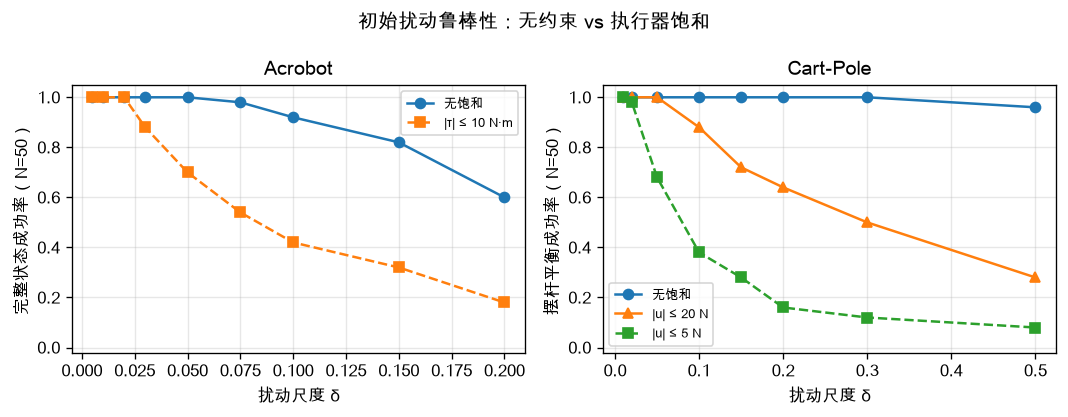

In [4]:

a_deltas = [0.005, 0.01, 0.02, 0.03, 0.05, 0.075, 0.1, 0.15, 0.2]
rng_a = np.random.default_rng(43)
a_draws = [rng_a.standard_normal(4) for _ in range(50)]
a_rob = []
for d in a_deltas:
    x0s = [acro.X_STAR + d * w for w in a_draws]
    sf = acro.summarize(acro.run_condition(x0s=x0s, sat_limit=1e6)[0])
    s10 = acro.summarize(acro.run_condition(x0s=x0s, sat_limit=10.0)[0])
    a_rob.append((d, sf["success_rate"], s10["success_rate"]))

c_deltas = [0.01, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5]
rng_c = np.random.default_rng(44)
c_draws = [rng_c.standard_normal(4) for _ in range(50)]
c_rob = []
for d in c_deltas:
    x0s = [cp.X_STAR + d * w for w in c_draws]
    sf = cp.summarize(cp.run_condition(x0s=x0s, lim=1e6)[0])
    s20 = cp.summarize(cp.run_condition(x0s=x0s, lim=20.0)[0])
    s5 = cp.summarize(cp.run_condition(x0s=x0s, lim=5.0)[0])
    c_rob.append((d, sf["pole_rate"], s20["pole_rate"], s5["pole_rate"]))

print("Acrobot: δ | 无饱和 | ±10 N·m")
for d, sf, s10 in a_rob:
    print(f"  {d:<6} {sf:.0%}  {s10:.0%}")
print("Cart-Pole: δ | 无饱和 | 20 N | 5 N  （摆杆平衡率）")
for d, sf, s20, s5 in c_rob:
    print(f"  {d:<5} {sf:.0%}  {s20:.0%}  {s5:.0%}")

fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))
axs[0].plot([r[0] for r in a_rob], [r[1] for r in a_rob], "o-", label="无饱和")
axs[0].plot([r[0] for r in a_rob], [r[2] for r in a_rob], "s--", label="|τ| ≤ 10 N·m")
axs[0].set_xlabel("扰动尺度 δ"); axs[0].set_ylabel("完整状态成功率（N=50）")
axs[0].set_ylim(-0.02, 1.05); axs[0].grid(alpha=0.3); axs[0].legend(fontsize=8)
axs[0].set_title("Acrobot")
axs[1].plot([r[0] for r in c_rob], [r[1] for r in c_rob], "o-", label="无饱和")
axs[1].plot([r[0] for r in c_rob], [r[2] for r in c_rob], "^-", label="|u| ≤ 20 N")
axs[1].plot([r[0] for r in c_rob], [r[3] for r in c_rob], "s--", label="|u| ≤ 5 N")
axs[1].set_xlabel("扰动尺度 δ"); axs[1].set_ylabel("摆杆平衡成功率（N=50）")
axs[1].set_ylim(-0.02, 1.05); axs[1].grid(alpha=0.3); axs[1].legend(fontsize=8)
axs[1].set_title("Cart-Pole")
fig.suptitle("初始扰动鲁棒性：无约束 vs 执行器饱和")
fig.tight_layout()
fig.savefig(os.path.join(FIG, "fig2_robustness.png"))
plt.show()


## 4. LQR 权重 R 的权衡

观察反馈增益、最慢闭环极点、控制需求和小车回中随 R 的变化。

Acrobot: R | ‖D‖ | 最慢|λ| | 成功率 | 峰值力矩
  0.1      577.1   2.248     65%    19.8 N·m
  1.0      328.2   2.242     63%    11.2 N·m
  10.0     289.7   2.240     62%     9.8 N·m
  100.0    285.5   2.233     62%     9.7 N·m
Cart-Pole: R | ‖D‖ | 最慢|λ| | 摆杆 | 完整 | 5s时|x|
  0.01     383.7   1.659  100%  100%   0.00 m
  0.1      297.7   0.951  100%  100%   0.00 m
  1.0      260.5   0.536  100%   99%   0.17 m
  10.0     242.2   0.302  100%   47%   0.53 m
  100.0    232.5   0.170  100%   27%   0.90 m


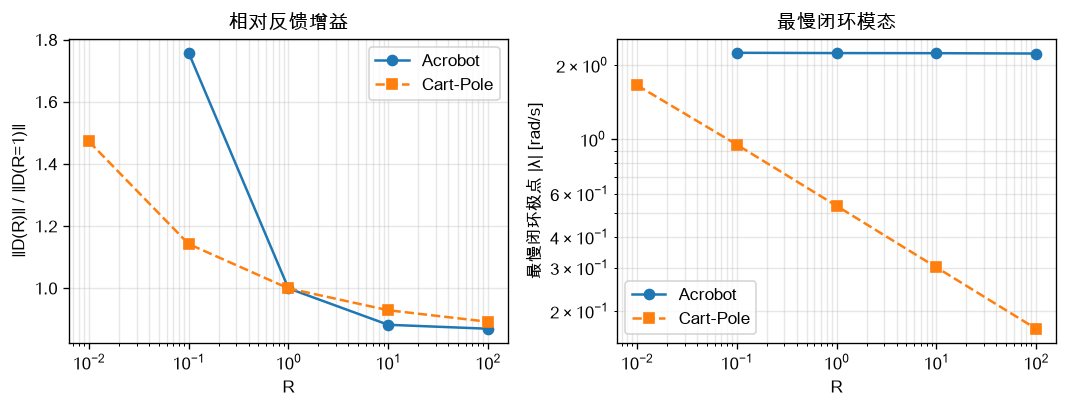

In [5]:

a_R = []
for Rv in [0.1, 1.0, 10.0, 100.0]:
    ctrl = acro.design_controller(R=np.array([[Rv]]))
    Dv = ctrl.D().ravel()
    eigs = np.linalg.eigvals(aL["A"] + aL["B"] @ Dv.reshape(1, -1))
    s = acro.summarize(acro.run_condition(R=np.array([[Rv]]), x0s=a_x0, sat_limit=10.0)[0])
    a_R.append((Rv, np.linalg.norm(Dv), np.min(np.abs(eigs)), s["success_rate"], s["med_max_ucmd_early"]))

c_R = []
for Rv in [0.01, 0.1, 1.0, 10.0, 100.0]:
    ctrl = cp.design(R=np.array([Rv]))
    Dv = ctrl.D().ravel()
    eigs = np.linalg.eigvals(cL["A"] + cL["B"] @ Dv.reshape(1, -1))
    s = cp.summarize(cp.run_condition(R=np.array([Rv]), x0s=c_x0, lim=1e6)[0])
    c_R.append((Rv, np.linalg.norm(Dv), np.min(np.abs(eigs)), s["pole_rate"], s["rate"], s["final_x"]))

print("Acrobot: R | ‖D‖ | 最慢|λ| | 成功率 | 峰值力矩")
for r in a_R:
    print(f"  {r[0]:<6} {r[1]:7.1f} {r[2]:7.3f} {r[3]:7.0%} {r[4]:7.1f} N·m")
print("Cart-Pole: R | ‖D‖ | 最慢|λ| | 摆杆 | 完整 | 5s时|x|")
for r in c_R:
    print(f"  {r[0]:<6} {r[1]:7.1f} {r[2]:7.3f} {r[3]:5.0%} {r[4]:5.0%} {r[5]:6.2f} m")

fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))
axs[0].plot([r[0] for r in a_R], [r[1] / a_R[1][1] for r in a_R], "o-", label="Acrobot")
axs[0].plot([r[0] for r in c_R], [r[1] / c_R[2][1] for r in c_R], "s--", label="Cart-Pole")
axs[0].set_xscale("log"); axs[0].set_xlabel("R"); axs[0].set_ylabel("‖D(R)‖ / ‖D(R=1)‖")
axs[0].grid(alpha=0.3, which="both"); axs[0].legend(); axs[0].set_title("相对反馈增益")
axs[1].plot([r[0] for r in a_R], [r[2] for r in a_R], "o-", label="Acrobot")
axs[1].plot([r[0] for r in c_R], [r[2] for r in c_R], "s--", label="Cart-Pole")
axs[1].set_xscale("log"); axs[1].set_yscale("log")
axs[1].set_xlabel("R"); axs[1].set_ylabel("最慢闭环极点 |λ| [rad/s]")
axs[1].grid(alpha=0.3, which="both"); axs[1].legend(); axs[1].set_title("最慢闭环模态")
fig.tight_layout()
fig.savefig(os.path.join(FIG, "fig3_weights.png"))
plt.show()


## 5. 物理参数敏感性

Acrobot 末端质量 $m_2$ 与 Cart-Pole 小车质量 $m_c$。

Acrobot: m2 | σ_min | ‖D‖ | 成功率 | 峰值力矩
  0.5   0.2067    153.2    98%     5.1 N·m
  1.0   0.0715    328.2    63%    11.2 N·m
  2.0   0.0215    864.3    35%    47.8 N·m
  4.0   0.0059   2655.7    10%   317.0 N·m
Cart-Pole: mc | σ_min | ‖D‖ | 摆杆 | 完整 | 峰值推力
  2.0   0.3286     79.8   100%   100%     5.6 N
  5.0   0.1659    149.4   100%   100%    10.3 N
  10.0  0.0907    260.5   100%    99%    18.4 N
  20.0  0.0475    476.6   100%    68%    34.2 N


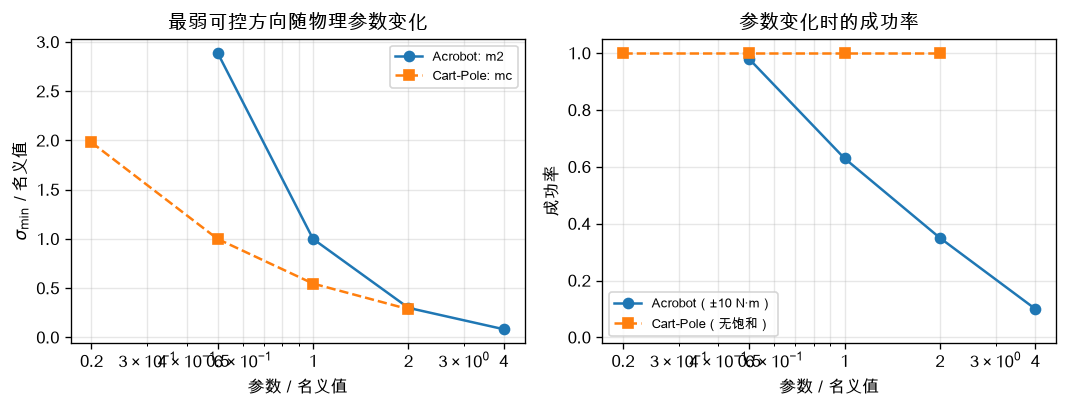

In [6]:

a_m2 = []
for v in [0.5, 1.0, 2.0, 4.0]:
    mods = {"m2": v}
    lv = acro.linear_data(mods)
    ctrl = acro.design_controller(mods)
    s = acro.summarize(acro.run_condition(params_mod=mods, x0s=a_x0, sat_limit=10.0)[0])
    a_m2.append((v, lv["sv"][-1], np.linalg.norm(ctrl.D()), s["success_rate"], s["med_max_ucmd_early"]))

c_mc = []
for v in [2.0, 5.0, 10.0, 20.0]:
    lv = cp.linear_data(mc=v)
    ctrl = cp.design(mc=v)
    s = cp.summarize(cp.run_condition(mc=v, x0s=c_x0, lim=1e6)[0])
    c_mc.append((v, lv["sv"][-1], np.linalg.norm(ctrl.D()), s["pole_rate"], s["rate"], s["peak"]))

print("Acrobot: m2 | σ_min | ‖D‖ | 成功率 | 峰值力矩")
for r in a_m2:
    print(f"  {r[0]:<5} {r[1]:.4f} {r[2]:8.1f} {r[3]:6.0%} {r[4]:7.1f} N·m")
print("Cart-Pole: mc | σ_min | ‖D‖ | 摆杆 | 完整 | 峰值推力")
for r in c_mc:
    print(f"  {r[0]:<5} {r[1]:.4f} {r[2]:8.1f} {r[3]:6.0%} {r[4]:6.0%} {r[5]:7.1f} N")

fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))
axs[0].plot([r[0] / 1.0 for r in a_m2], [r[1] / a_m2[1][1] for r in a_m2], "o-", label="Acrobot: m2")
axs[0].plot([r[0] / 10.0 for r in c_mc], [r[1] / c_mc[1][1] for r in c_mc], "s--", label="Cart-Pole: mc")
axs[0].set_xscale("log"); axs[0].set_xticks([0.2, 0.5, 1, 2, 4])
axs[0].set_xticklabels(["0.2", "0.5", "1", "2", "4"])
axs[0].set_xlabel("参数 / 名义值"); axs[0].set_ylabel(r"$\sigma_{\min}$ / 名义值")
axs[0].grid(alpha=0.3, which="both"); axs[0].legend(fontsize=8)
axs[0].set_title("最弱可控方向随物理参数变化")
axs[1].plot([r[0] / 1.0 for r in a_m2], [r[3] for r in a_m2], "o-", label="Acrobot（±10 N·m）")
axs[1].plot([r[0] / 10.0 for r in c_mc], [r[3] for r in c_mc], "s--", label="Cart-Pole（无饱和）")
axs[1].set_xscale("log"); axs[1].set_xticks([0.2, 0.5, 1, 2, 4])
axs[1].set_xticklabels(["0.2", "0.5", "1", "2", "4"])
axs[1].set_xlabel("参数 / 名义值"); axs[1].set_ylabel("成功率")
axs[1].set_ylim(-0.02, 1.05); axs[1].grid(alpha=0.3, which="both"); axs[1].legend(fontsize=8)
axs[1].set_title("参数变化时的成功率")
fig.tight_layout()
fig.savefig(os.path.join(FIG, "fig4_physical.png"))
plt.show()


## 结论

1. **可控性**：两者线性化后都满秩（rank = 4），但 Acrobot 的条件数是 7154，Cart-Pole 只有 47.7；归一化最小奇异值分别为 $1.4\times10^{-4}$ 和 $2.1\times10^{-2}$。Acrobot 的“弱可控”程度显著更高。
2. **非最小相位**：两者都有右半平面零点（Acrobot：+2.05、+2.28；Cart-Pole：+4.43），闭环必须让状态先向“错误方向”移动，因此 LQR 轨迹会出现明显反向偏移。
3. **零模态差异**：Cart-Pole 有两个零特征值（小车位置的积分链），对应一对慢闭环极点；Acrobot 没有零模态，最慢闭环极点约为 2.24 rad/s。所以 Cart-Pole 的主要问题是“小车回中慢”，Acrobot 的主要问题是“执行器力矩不够”。
4. **权重 R**：两者增益都存在有限下限（Acrobot 约 286，Cart-Pole 约 233），因为开环不稳定极点必须被镇定；增大 R 会显著拖慢 Cart-Pole 的小车回中（最慢极点从 1.66 降到 0.17），但对摆杆平衡几乎没影响。
5. **饱和是决定性因素**：Acrobot 原代码的 ±10 N·m 使 0.05 级扰动成功率从 98% 降到 63%；Cart-Pole 原代码没有饱和，加入 20 N 后摆杆成功率降到 90%，5 N 只剩 36%。实际系统必须做饱和感知设计。
6. **物理参数**：Acrobot 对末端质量 $m_2$ 极敏感（0.5→4 kg：σ_min 下降 35 倍，成功率 98%→10%）；Cart-Pole 对小车质量 $m_c$ 敏感（2→20 kg：所需推力 5.6→34 N，完整状态成功率 100%→68%），但摆杆本身仍能平衡。
